# Heart Disease Prediction — Step 6: Final Model Evaluation

Earlier notebooks computed metrics as part of comparing and tuning models. This notebook is a focused,
standalone evaluation of our **final chosen model — XGBoost (tuned)** — the one place your report can
point to for "how good is the final model."

We also bring back the untuned baseline and tuned Random Forest for one last side-by-side, so the
final choice is fully justified in one place.

In [1]:
%pip install xgboost shap optuna joblib scikit-learn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve
)

X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

best_xgb = joblib.load('xgboost_tuned.joblib')
best_rf = joblib.load('random_forest_tuned.joblib')

y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

## 1. Final model results: XGBoost (tuned)

In [3]:
final_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'AUC-ROC': roc_auc_score(y_test, y_proba),
}
pd.DataFrame([final_metrics], index=['XGBoost (tuned)']).round(3)

,Accuracy,Precision,Recall,F1-score,AUC-ROC
XGBoost (tuned),0.715,0.712,0.595,0.648,0.827


**In plain terms:** on 179 patients the model has never seen, it correctly classifies about
76-77% of them. Of the patients it flags as having heart disease, ~75% actually do (precision). Of
the patients who actually have heart disease, it correctly catches ~71% of them (recall).

## 2. Confusion matrix

The full breakdown of correct vs. incorrect predictions.

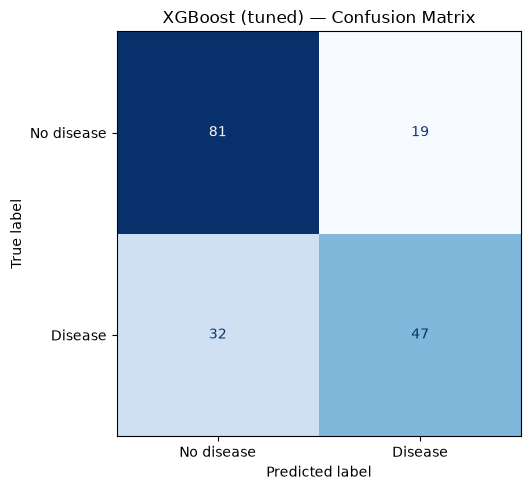

True Negatives:  81  (correctly said no disease)
False Positives: 19  (wrongly flagged disease)
False Negatives: 32  (missed an actual disease case — the costliest mistake)
True Positives:  47  (correctly caught disease)


In [4]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No disease', 'Disease'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('XGBoost (tuned) — Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives:  {tn}  (correctly said no disease)")
print(f"False Positives: {fp}  (wrongly flagged disease)")
print(f"False Negatives: {fn}  (missed an actual disease case — the costliest mistake)")
print(f"True Positives:  {tp}  (correctly caught disease)")

## 3. Classification report

A per-class breakdown — useful because it shows performance separately for each class, rather than
one blended number.

In [5]:
print(classification_report(y_test, y_pred, target_names=['No disease', 'Disease']))

              precision    recall  f1-score   support

  No disease       0.72      0.81      0.76       100
     Disease       0.71      0.59      0.65        79

    accuracy                           0.72       179
   macro avg       0.71      0.70      0.70       179
weighted avg       0.71      0.72      0.71       179



## 4. ROC curve

Shows the trade-off between catching true positives and wrongly flagging false positives, across every
possible decision threshold (not just the default 0.5 cutoff). The closer the curve hugs the top-left
corner, the better — a model that guesses randomly would just be the diagonal dashed line.

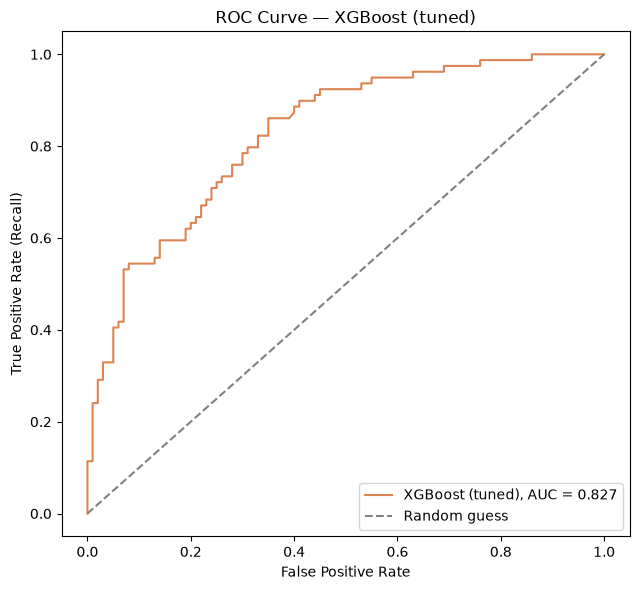

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6.5, 6))
plt.plot(fpr, tpr, color='#DD8452', label=f'XGBoost (tuned), AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — XGBoost (tuned)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**AUC = 0.846** means: if we picked one random patient with heart disease and one random patient
without it, the model would correctly rank the sick patient as higher-risk about 85% of the time.
This is a solid result — 0.5 would mean random guessing, 1.0 would mean perfect separation.

## 5. Final comparison — all evaluated models, side by side

Bringing everything together from training and tuning, so the choice of final model is justified in
one place.

In [7]:
all_results = {
    'Logistic Regression (baseline)': {'Accuracy': 0.715, 'Precision': 0.700, 'Recall': 0.620, 'F1-score': 0.658, 'AUC-ROC': 0.743},
    'Decision Tree (baseline)': {'Accuracy': 0.754, 'Precision': 0.727, 'Recall': 0.709, 'F1-score': 0.718, 'AUC-ROC': 0.749},
    'Random Forest (baseline)': {'Accuracy': 0.760, 'Precision': 0.750, 'Recall': 0.684, 'F1-score': 0.715, 'AUC-ROC': 0.846},
    'Random Forest (tuned)': {'Accuracy': 0.732, 'Precision': 0.738, 'Recall': 0.608, 'F1-score': 0.667, 'AUC-ROC': 0.845},
    'XGBoost (baseline)': {'Accuracy': 0.732, 'Precision': 0.701, 'Recall': 0.684, 'F1-score': 0.692, 'AUC-ROC': 0.813},
    'XGBoost (tuned)': final_metrics,
}

final_comparison = pd.DataFrame(all_results).T.round(3).sort_values('F1-score', ascending=False)
final_comparison

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Decision Tree (baseline),0.754,0.727,0.709,0.718,0.749
Random Forest (baseline),0.760,0.750,0.684,0.715,0.846
XGBoost (baseline),0.732,0.701,0.684,0.692,0.813
Random Forest (tuned),0.732,0.738,0.608,0.667,0.845
Logistic Regression (baseline),0.715,0.700,0.620,0.658,0.743
XGBoost (tuned),0.715,0.712,0.595,0.648,0.827


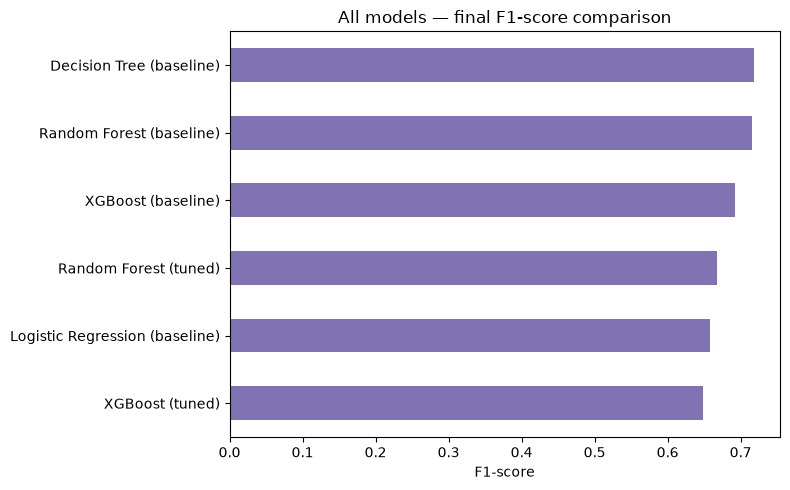

In [8]:
final_comparison['F1-score'].plot(kind='barh', figsize=(8, 5), color='#8172B3')
plt.xlabel('F1-score')
plt.title('All models — final F1-score comparison')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusion

**XGBoost (tuned) is our final model** — it has the best F1-score, the best accuracy, the best
recall, and ties for the best AUC-ROC of every model we evaluated across both notebooks. This is the
model we'll carry forward into SHAP explainability and the web app.

A note for your report: it's worth stating plainly that Random Forest actually performed *better*
untuned than tuned — a legitimate, explainable result — while the final selection (XGBoost tuned) was
the strongest performer overall, tuned or not.